In [ ]:
from google.colab import auth, drive
from oauth2client.client import GoogleCredentials
import pandas as pd
import io

# auth.authenticate_user()
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# membuat dataset
import pandas as pd

df = pd.read_csv('/content/drive/My Drive/Colab Notebooks/data_distribution_handson.csv')
df

,Name,Years of Experience,Monthly Salary (in Dollars),Hometown
0,Liam Carter,3.9,2063,Tokyo
1,Aisha Rahman,3.2,1747,Paris
2,Mateo Alvarez,4.0,2192,New York City
3,Sophie Dubois,3.7,2004,Sydney
4,Ethan Walker,3.6,2036,Tokyo
5,Arjun Patel,2.9,1564,Sydney
6,Isabella Rossi,4.3,2423,Paris
7,Noah Kim,4.4,2625,New York City
8,Maya Singh,2.7,1442,Tokyo
9,Lucas Müller,3.7,1944,Paris


In [ ]:
import pandas as pd

# https://docs.google.com/spreadsheets/d/1l0m0X75p3yguIxj-7KI9D-FzUQ9UG9pevvj66SY6F4I/edit?gid=0#gid=0
google_sheets_link = 'https://docs.google.com/spreadsheets/d/1l0m0X75p3yguIxj-7KI9D-FzUQ9UG9pevvj66SY6F4I/export?format=csv'
df2 = pd.read_csv(google_sheets_link, sep=',')
df2

,Name,Years of Experience,Monthly Salary (in Dollars),Hometown
0,Liam Carter,3.9,2063,Tokyo
1,Aisha Rahman,3.2,1747,Paris
2,Mateo Alvarez,4.0,2192,New York City
3,Sophie Dubois,3.7,2004,Sydney
4,Ethan Walker,3.6,2036,Tokyo
5,Arjun Patel,2.9,1564,Sydney
6,Isabella Rossi,4.3,2423,Paris
7,Noah Kim,4.4,2625,New York City
8,Maya Singh,2.7,1442,Tokyo
9,Lucas Müller,3.7,1944,Paris


# Statistik Deskripsi Dasar

In [ ]:
df.describe()

,Years of Experience,Monthly Salary (in Dollars)
count,30.000000,30.000000
mean,3.696667,2057.366667
std,0.559854,368.970748
min,2.700000,1442.000000
25%,3.225000,1764.000000
50%,3.700000,2043.500000
75%,4.075000,2390.750000
max,4.700000,2757.000000


`df.describe()` memungkinkan kita untuk mendapat ringkasan statistik deskriptif.

- count: jumlah data (non-null)
- mean: rata-rata
- std: standar deviasi
- min: nilai minimum
- 25%: kuartil pertama
- 50%: median (kuartil kedua)
- 75%: kuartil ketiga
- max: nilai maksimum

# Mean, Median, Modus

In [ ]:
print("Rata-rata Years of Experience:", df['Years of Experience'].mean())
print("Median Years of Experience:", df['Years of Experience'].median())
print("Modus Hometown:", df['Hometown'].mode()[0])

Rata-rata Years of Experience: 3.6966666666666668
Median Years of Experience: 3.7
Modus Hometown: Paris


In [ ]:
print("Mean Monthly Salary (in Dollars):", df['Monthly Salary (in Dollars)'].mean())
print("Median Monthly Salary (in Dollars):", df['Monthly Salary (in Dollars)'].median())

Mean Monthly Salary (in Dollars): 2057.366666666667
Median Monthly Salary (in Dollars): 2043.5


# Varians dan Standar Deviasi

In [ ]:
print("Varians Gaji Bulanan:", df['Monthly Salary (in Dollars)'].var())
print("Standar Deviasi Gaji Bulanan:", df['Monthly Salary (in Dollars)'].std())


Varians Gaji Bulanan: 136139.4126436782
Standar Deviasi Gaji Bulanan: 368.9707476801897


Interpretasi

Dengan:
- Rata-rata Gaji Bulanan : $ 2057
- Standar deviasi: $ 369

Berarti sebagian besar data gaji bulanan berada dalam rentang:
$ (2057-369) sampai $ (2057+369)
(Ini maksudnya dari mean ± 1 standar deviasi ==> 2057 ± 369)

In [ ]:
print("Varians Years of Experience:", df['Years of Experience'].var())
print("Standar Deviasi Years of Experience:", df['Years of Experience'].std())


Varians Years of Experience: 0.31343678160919547
Standar Deviasi Years of Experience: 0.5598542503269895


Interpretasi:

Pengalaman kerja dalam dataset tersebar sekitar ±0.55 tahun dari rata-rata usia.

# Expected Value (Rata-rata Pembelian)

Untuk menghitung expected value kita memerlukan data tambahan yaitu probabilitas.

Rumus expected value adalah $E(X) = \sum_{i=1}^{n} x_i P(x_i)$

$P(x_i)$ artinya probabilitas terjadinya $x_i$. Misal, probabilitas terjadinya total belanja Rp 200.000.

Probabilitas ini bisa didapat dari beberapa cara, yaitu:
- Data historis/observasi
  - contoh: dari 100 hari berjualan ..., selama 5 tahun berjualan ... hingga didapat probabilitas bahwa sekitar 20% pelanggan itu berbelanja sebesar 100rb
- Asumsi atau estimasi berdasarkan kategori
  - contoh: ternyata 20% pelanggan biasanya hanya belanja 1 barang (anggaplah barangnya mayoritas seharga Rp100.000), 50% beli 2 barang (Rp200.000), dll.
  - jadi bisa berupa asumsi teoritis atau estimasi berdasarkan hal tertentu
- Model prediktif

Di kasus ini, disediakan probabilitasnya. Anggaplah data ini merupakan hasil dari observasi yang sudah dilakukan sebelumnya.

In [ ]:
# membuat tambahan data untuk mengetahui probabilitas/peluang total belanja.
data_prob = {
    "Gaji_Bulanan": [2000, 2100, 2200],
    "Probabilitas": [0.25, 0.45, 0.3]
}

df_prob = pd.DataFrame(data_prob)
df_prob

,Gaji_Bulanan,Probabilitas
0,2000,0.25
1,2100,0.45
2,2200,0.30


In [ ]:
# menghitung x dikali p (gaji bulanan dikali probabilitasnya)
df_prob['xp'] = df_prob['Gaji_Bulanan'] * df_prob['Probabilitas']
df_prob

,Gaji_Bulanan,Probabilitas,xp
0,2000,0.25,500.0
1,2100,0.45,945.0
2,2200,0.30,660.0


In [ ]:
expected_value = df_prob["xp"].sum()

print("Expected Value ($):", expected_value)


Expected Value ($): 2105.0


Interpretasi:
* Rata-rata belanja (jangka panjang) yang bisa diperkirakan dari pelanggan adalah Rp210,000
* Bisa jadi dasar promosi seperti “Gratis ongkir untuk pembelanjaan di atas Rp250,000” atau strategi lainnya yang mendorong pelanggan untuk bertransaksi lebih dari rata-rata tersebut.

# Kovariansi dan Korelasi

In [ ]:
print("Kovarians:", df['Years of Experience'].cov(df['Monthly Salary (in Dollars)']))
print("Korelasi:", df['Years of Experience'].corr(df['Monthly Salary (in Dollars)']))

Kovarians: 183.31505747126442
Korelasi: 0.8874241093786055


- Kovarians > 0 =  positif
- Korelasi 0.92 = sangat kuat. Semakin tinggi usia, semakin tinggi total belanja.

Interpretasi:

Terdapat hubungan linier yang sangat kuat dan positif antara usia dan total belanja. Hal ini menunjukkan bahwa pelanggan yang lebih tua cenderung membelanjakan lebih banyak dibandingkan pelanggan yang lebih muda.

# Distribusi Normal

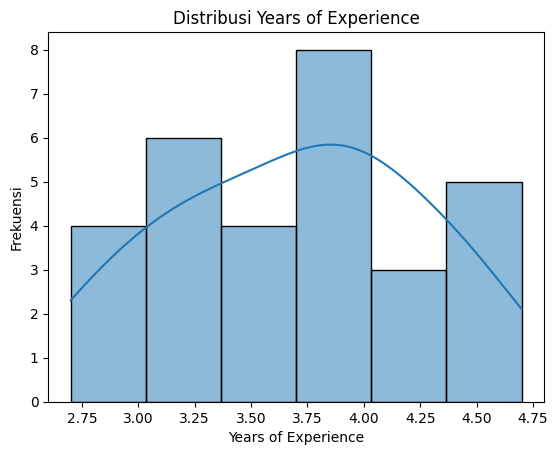

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Distribusi Years of Experience
sns.histplot(df['Years of Experience'], kde=True)
plt.title("Distribusi Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Frekuensi")
plt.show()


In [ ]:
from scipy.stats import skew
from scipy.stats import kurtosis
skew_yoe = skew(df['Years of Experience'])
kurtosis_yoe = kurtosis(df['Years of Experience'])
print(skew_yoe)
print(kurtosis_yoe)

-0.0899600832513749
-0.9685713468107009


Dari histogram di atas, terlihat bahwa distribusi usia merupakan distribusi normal. Bentuknya cukup simetris. Selain itu, dilihat dari deskripsi statistiknya memang menjadi indikasi bahwa distribusi usia ini adalah distribusi normal.

- Mean ≈ Median --> indikasi distribusi simetris
- Jarak ke kiri (31.57 – 23 = 8.57) mirip ke kanan (40 – 31.57 = 8.43)--> penyebaran cukup seimbang
- Tidak nampak outlier

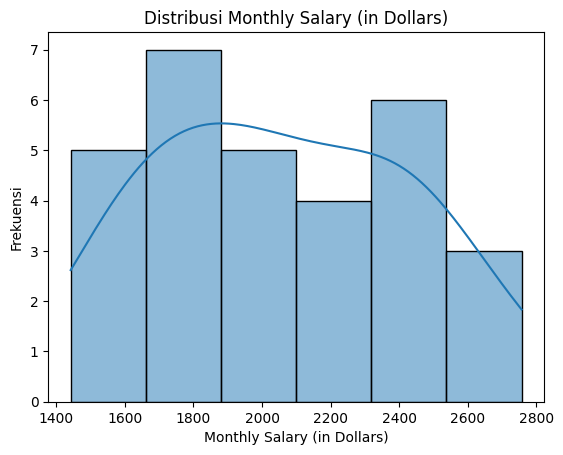

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Distribusi Monthly Salary (in Dollars)
sns.histplot(df['Monthly Salary (in Dollars)'], kde=True)
plt.title("Distribusi Monthly Salary (in Dollars)")
plt.xlabel("Monthly Salary (in Dollars)")
plt.ylabel("Frekuensi")
plt.show()


In [ ]:
from scipy.stats import skew
from scipy.stats import kurtosis
skew_ms = skew(df['Monthly Salary (in Dollars)'])
kurtosis_ms = kurtosis(df['Monthly Salary (in Dollars)'])
print(skew_ms)
print(kurtosis_ms)

0.12101952964598625
-1.0618459321169966


Distribusi total belanja bukanlah distribusi normal, melainkan right-skewed distribution. Right-skewed (juga disebut positively skewed) artinya sebagian besar data berkumpul di sisi kiri grafik (nilai kecil), dan ada beberapa data bernilai besar yang "menarik" ekornya ke kanan.

Salah satu cirinya adalah Mean > Median > Mode. Dan di kasus data ini,
- Median total belanja: 320.000
- Mean total belanja: 363.571
- Maksimum: 600.000 (jauh dari mayoritas data)

Nah, ini tanda bahwa ada sebagian kecil pelanggan yang belanjanya jauh lebih tinggi dari yang lain, jadi bentuk distribusinya right-skewed.

# Z-Score

In [ ]:
df

,Name,Years of Experience,Monthly Salary (in Dollars),Hometown,Z_Score_Salary
0,Liam Carter,3.9,2063,Tokyo,0.015268
1,Aisha Rahman,3.2,1747,Paris,-0.841169
2,Mateo Alvarez,4.0,2192,New York City,0.364889
3,Sophie Dubois,3.7,2004,Sydney,-0.144637
4,Ethan Walker,3.6,2036,Tokyo,-0.057909
5,Arjun Patel,2.9,1564,Sydney,-1.337143
6,Isabella Rossi,4.3,2423,Paris,0.990955
7,Noah Kim,4.4,2625,New York City,1.538424
8,Maya Singh,2.7,1442,Tokyo,-1.667793
9,Lucas Müller,3.7,1944,Paris,-0.307251


In [ ]:
# untuk menghitung z-score perlu mean dan std-nya. Kita masukkan ke dalam variabel

mean_belanja = df['Monthly Salary (in Dollars)'].mean()
std_belanja = df['Monthly Salary (in Dollars)'].std()


# menghitung z-score
# total belanja sebagai x

df['Z_Score_Salary'] = (df['Monthly Salary (in Dollars)'] - mean_belanja) / std_belanja

In [ ]:
df

,Name,Years of Experience,Monthly Salary (in Dollars),Hometown,Z_Score_Salary
0,Liam Carter,3.9,2063,Tokyo,0.015268
1,Aisha Rahman,3.2,1747,Paris,-0.841169
2,Mateo Alvarez,4.0,2192,New York City,0.364889
3,Sophie Dubois,3.7,2004,Sydney,-0.144637
4,Ethan Walker,3.6,2036,Tokyo,-0.057909
5,Arjun Patel,2.9,1564,Sydney,-1.337143
6,Isabella Rossi,4.3,2423,Paris,0.990955
7,Noah Kim,4.4,2625,New York City,1.538424
8,Maya Singh,2.7,1442,Tokyo,-1.667793
9,Lucas Müller,3.7,1944,Paris,-0.307251


Interpretasi:
- Ani (-0.95): Belanja Ani sekitar 1 standar deviasi di bawah rata-rata. Artinya, belanja dia lebih kecil dibanding kebanyakan orang di data ini.

- Eka (+1.98): Belanja Eka sekitar 2 standar deviasi di atas rata-rata, bisa dianggap belanjanya sangat tinggi dibanding yang lain.

- Z-score dekat nol (misalnya 0.1 atau -0.2) berarti belanja mereka sangat dekat dengan rata-rata.